# TMR structure and distance correlations

This notebook colors the fitted TMR structure by normalized RMSF and compares the three spin-label distances across conformers. Run the code cells from top to bottom. The structure view uses py3Dmol's native notebook output; the color scale is placed next to it without embedding the viewer in an ipywidgets container.


In [29]:
from copy import copy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import py3Dmol
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_hex


## Load and color the structure

The `CM` residue names are temporarily changed to `C` in the display copy of the PDB so the cartoon remains continuous. Former `CM` residues and the TMR dye are then shown as sticks. RMSF values are mapped from blue through light gray to red.


In [33]:
data_dir = Path.cwd() / "Data"
pdb_path = data_dir / "Fit_wTMR_reference_frame.pdb"
rmsf_path = data_dir / "Fit_wTMR_RMSF_normalized.txt"

table = np.loadtxt(rmsf_path)
rmsf = np.atleast_1d(table)
min_rmsf, max_rmsf = np.nanmin(rmsf), np.nanmax(rmsf)

colors = [(0, 0.2, 0.8), (0.90, 0.90, 0.90), (0.6350, 0.0780, 0.1840)]
cmap = LinearSegmentedColormap.from_list("blue_white_red", list(zip([0, 0.5, 1], colors)))
norm = Normalize(vmin=min_rmsf, vmax=max_rmsf)

def rmsf_color(resi):
    """Return the normalized RMSF color for a 1-based residue, if available."""
    idx = resi - 1
    if idx < 0 or idx >= len(rmsf) or np.isnan(rmsf[idx]):
        return None
    return to_hex(cmap(norm(rmsf[idx])))

# Rename CM to C only in the copy sent to the molecular viewer.
lines = []
cm_resi = set()
for line in pdb_path.read_text().splitlines():
    if line.startswith(("ATOM", "HETATM")) and line[17:20].strip() == "CM":
        cm_resi.add(int(line[22:26]))
        line = line[:17] + "C  " + line[20:]
    lines.append(line)
pdb_data = "\n".join(lines)
cm_resi = sorted(cm_resi)
resids = sorted({int(line[22:26]) for line in lines if line.startswith(("ATOM", "HETATM"))})

view = py3Dmol.view(width=800, height=700)
view.addModel(pdb_data, "pdb")
view.setStyle({"cartoon": {"color": "lightgrey"}})
for resi in resids:
    color = rmsf_color(resi)
    if color:
        view.setStyle({"resi": resi}, {"cartoon": {"color": color}})
for resi in cm_resi:
    view.addStyle(
        {"resi": resi, "not": {"elem": "H"}},
        {"stick": {"color": rmsf_color(resi) or "magenta", "radius": 0.2}},
    )

tmr_color = rmsf_color(81)
if tmr_color:
    view.setStyle({"resn": "TMR"}, {"cartoon": {"hidden": True}})
    view.addStyle(
        {"resn": "TMR", "not": {"elem": "H"}},
        {"stick": {"color": tmr_color, "radius": 0.2}},
    )

view.setBackgroundColor("white")
view.zoomTo()


You appear to be running in JupyterLab (or JavaScript failed to load for some other reason). You need to install the 3dmol extension: 
 jupyter labextension install jupyterlab_3dmol

## Display the structure and distance correlations

The scale bar is rendered in the same HTML row as the py3Dmol viewer (This differs from the original analysis, as something changed in the pymol implementation in python). The lower figure compares each pair of spin-label distances (`C12C30`, `C12C47`, `C30C47`) across all finite conformers. Each plot includes a least-squares fit and its coefficient of determination (R²); there is no distance threshold filter. The distance data differs slightly from the published data


You appear to be running in JupyterLab (or JavaScript failed to load for some other reason). You need to install the 3dmol extension: 
 jupyter labextension install jupyterlab_3dmol 
 
 
 
 14.11 
 
 4.78 
 
 RMSF (normalized)

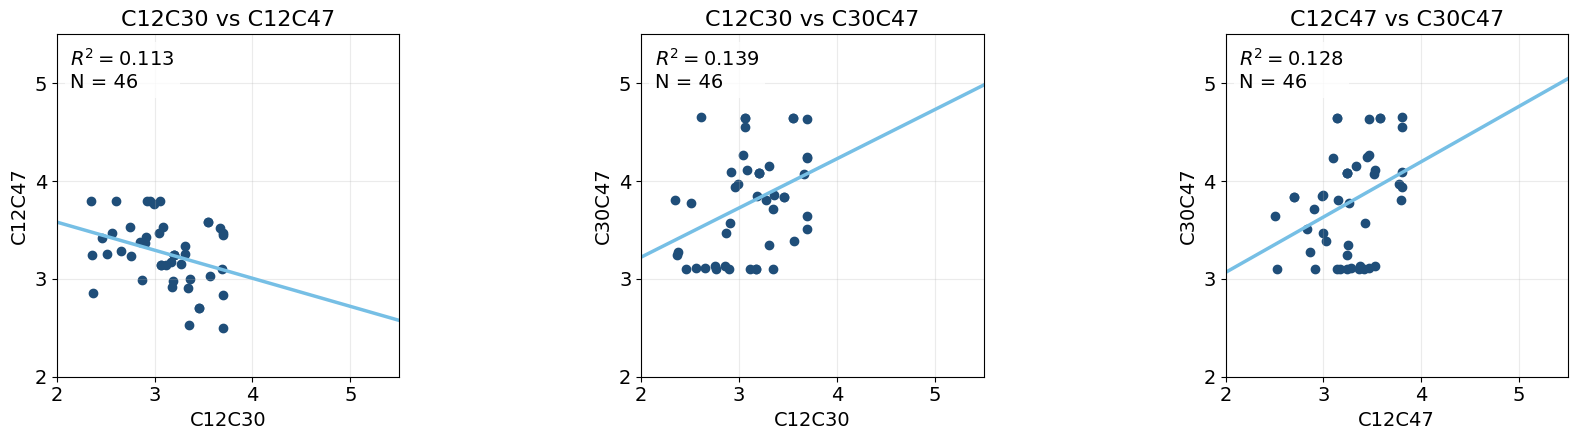

In [32]:
# Add a standalone RMSF scale beside the native py3Dmol viewer output.
bar_html = f"""
<div style="display:flex; align-items:center; gap:10px; height:700px; padding:0 12px; font:13px sans-serif;">
  <div style="display:flex; flex-direction:column; align-items:center; gap:8px; height:520px;">
    <span>{max_rmsf:.2f}</span>
    <div style="width:24px; flex:1; border:1px solid #555; background:linear-gradient(to top, {to_hex(cmap(0.0))} 0%, {to_hex(cmap(0.5))} 50%, {to_hex(cmap(1.0))} 100%);"></div>
    <span>{min_rmsf:.2f}</span>
  </div>
  <span style="writing-mode:vertical-rl; transform:rotate(180deg);">RMSF (normalized)</span>
</div>
"""
viewer_with_bar = copy(view)
viewer_open = '<div id="3dmolviewer_UNIQUEID"  style="position: relative; width: 800px; height: 700px;">'
viewer_close = '</div>\n<script>'
if viewer_open not in viewer_with_bar.startjs or viewer_close not in viewer_with_bar.startjs:
    raise RuntimeError("Could not locate the py3Dmol viewer container to attach the RMSF scale.")
viewer_with_bar.startjs = viewer_with_bar.startjs.replace(
    viewer_open,
    '<div style="display:flex; align-items:center; width:max-content;">' + viewer_open,
    1,
)
viewer_with_bar.startjs = viewer_with_bar.startjs.replace(
    viewer_close,
    '</div>' + bar_html + '</div>\n<script>',
    1,
)
display(viewer_with_bar)

# Read conformer-wise distances and omit only rows containing non-finite values.
distance_data = np.genfromtxt(
    data_dir / "Fit_wTMR_SpinLabelDistances.csv",
    delimiter=",",
    names=True,
    dtype=float,
    encoding="utf-8",
)
required_columns = ("C12C30", "C12C47", "C30C47")
if distance_data.dtype.names is None or not set(required_columns).issubset(distance_data.dtype.names):
    raise ValueError(f"Distance CSV must contain columns {list(required_columns)}")
distances = {name: np.atleast_1d(distance_data[name]) for name in required_columns}
valid_rows = np.logical_and.reduce([np.isfinite(distances[name]) for name in required_columns])
if np.count_nonzero(valid_rows) < 2:
    raise ValueError("At least two finite conformers are required to fit the correlations.")

plot_pairs = (("C12C30", "C12C47"), ("C12C30", "C30C47"), ("C12C47", "C30C47"))
scatter_fig, scatter_axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (x_name, y_name) in zip(scatter_axes, plot_pairs):
    x_values = distances[x_name][valid_rows]
    y_values = distances[y_name][valid_rows]
    slope, intercept = np.polyfit(x_values, y_values, 1)
    fitted_values = slope * x_values + intercept
    total_variation = np.sum((y_values - y_values.mean()) ** 2)
    if np.isclose(total_variation, 0):
        raise ValueError(f"Cannot calculate R-squared for constant values in {y_name}.")
    r_squared = 1 - np.sum((y_values - fitted_values) ** 2) / total_variation

    ax.scatter(x_values, y_values, alpha=1.0, color="#1f4e79")
    x_fit = np.linspace(2, 5.5, 100)
    ax.plot(x_fit, slope * x_fit + intercept, color="#76bfe5", linewidth=2.5)
    ax.set_title(f"{x_name} vs {y_name}", fontsize=16)
    ax.set_xlabel(x_name, fontsize=14)
    ax.set_ylabel(y_name, fontsize=14)
    ax.tick_params(axis="both", labelsize=14)
    ax.set_xlim(2, 5.5)
    ax.set_ylim(2, 5.5)
    ax.set_xticks(np.arange(2, 5.6, 1))
    ax.set_yticks(np.arange(2, 5.6, 1))
    ax.set_aspect("equal", adjustable="box")
    ax.text(
        0.04,
        0.96,
        f"$R^2 = {r_squared:.3f}$\nN = {x_values.size}",
        transform=ax.transAxes,
        va="top",
        fontsize=14,
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
    )
    ax.grid(True, alpha=0.25)

scatter_fig.tight_layout()
plt.show()
